# 02 - Constraint-Limited Operation (S2)

**Question:** as loading pushes the operating point toward the voltage/current/DC-link limits
(but before any hard limit is actually crossed), does the Safety-Margin Index fall and the CRI
correctly move the system from Activate toward Monitor/Delay -- and does safe micro-probing
automatically shrink in step with SMI, exactly as Eq. (10) requires?

Outputs: `results/results_S2.csv`, `Figures/Fig_constraint_margin.pdf`, `Figures/Fig_probe_scaling.pdf`.

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cri_microgrid.config import (PlantParams, ControllerParams, ConstraintParams, CRIParams,
                                   ProbeParams, ProfileParams, SimulationParams)
from cri_microgrid import scenarios, sim, metrics, validation, plotstyle

plotstyle.apply_style()
RESULTS_DIR = os.path.abspath("../results")
FIG_DIR = os.path.abspath("../Figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

pp = PlantParams()
cp = ControllerParams()
cons = ConstraintParams()
crip = CRIParams()
probep = ProbeParams()
prof = ProfileParams()
SEED = 1

In [3]:
scenario = scenarios.build_S2(pp, prof, T_end=40.0)
simp = SimulationParams(T_end=scenario.T_end, seed=SEED, strategy="cri")
log = sim.run_closed_loop(scenario, pp, cp, cons, crip, probep, simp)
print(scenario.name, "-", scenario.description)
print(f"Load ramps from t={scenario.event_time:g}s to t={scenario.event_end:g}s")

S2 - High loading pushing toward voltage/current/DC-link limits.
Load ramps from t=6s to t=34s


## Figure 3 -- Constraint margins vs. CRI (2x2, all in pu)

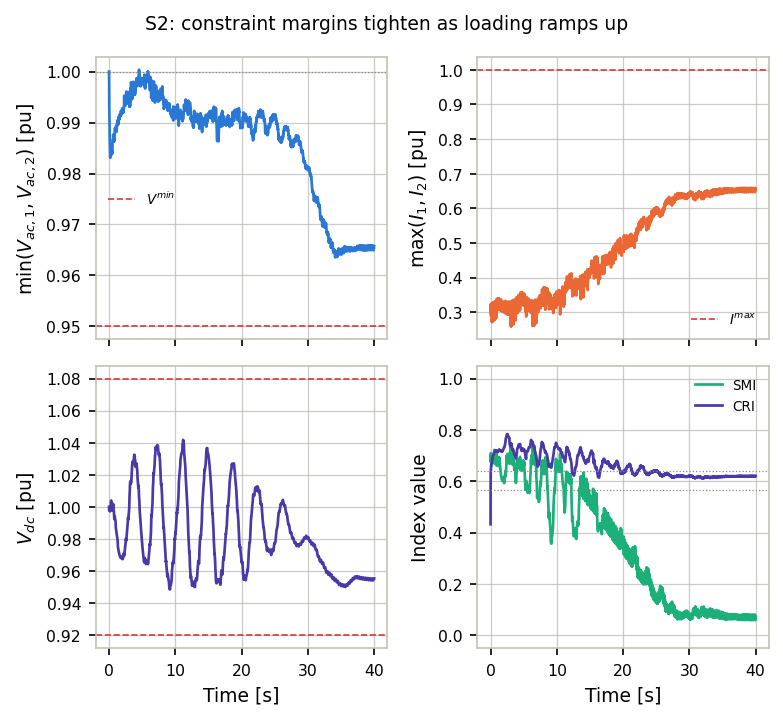

In [4]:
t = log["t"]
min_V = np.minimum(log["V1"], log["V2"])
max_I = np.maximum(log["I1"], log["I2"])

fig, axs = plt.subplots(2, 2, figsize=plotstyle.FIGSIZE_2x2, sharex=True)

ax = axs[0, 0]
ax.plot(t, min_V, color=plotstyle.CAT["blue"])
ax.axhline(cons.Vac_min, color=plotstyle.STATUS["Reject"], lw=0.8, ls="--", label="$V^{min}$")
ax.axhline(1.0, color=plotstyle.INK_MUTED, lw=0.6, ls=":")
ax.set_ylabel("min($V_{ac,1}, V_{ac,2}$) [pu]"); ax.legend(frameon=False, fontsize=6.5)

ax = axs[0, 1]
ax.plot(t, max_I, color=plotstyle.CAT["orange"])
ax.axhline(cons.I_max, color=plotstyle.STATUS["Reject"], lw=0.8, ls="--", label="$I^{max}$")
ax.set_ylabel("max($I_1,I_2$) [pu]"); ax.legend(frameon=False, fontsize=6.5)

ax = axs[1, 0]
ax.plot(t, log["Vdc"], color=plotstyle.CAT["violet"])
ax.axhline(cons.Vdc_min, color=plotstyle.STATUS["Reject"], lw=0.8, ls="--")
ax.axhline(cons.Vdc_max, color=plotstyle.STATUS["Reject"], lw=0.8, ls="--")
ax.set_ylabel("$V_{dc}$ [pu]"); ax.set_xlabel("Time [s]")

ax = axs[1, 1]
ax.plot(t, log["SMI"], color=plotstyle.INDICATOR_COLORS["SMI"], label="SMI")
ax.plot(t, log["CRI"], color=plotstyle.INDICATOR_COLORS["CRI"], label="CRI")
for eta, lbl in [(crip.eta_A, "$\\eta_A$"), (crip.eta_M, "$\\eta_M$")]:
    ax.axhline(eta, color=plotstyle.INK_MUTED, lw=0.6, ls=":")
ax.set_ylabel("Index value"); ax.set_xlabel("Time [s]"); ax.set_ylim(-0.05, 1.05)
ax.legend(frameon=False, fontsize=6.5)

fig.suptitle("S2: constraint margins tighten as loading ramps up", fontsize=9)
plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_constraint_margin.pdf"))
plt.show()

## Figure 3 (v2) -- clarity pass, same conventions as Figs. 1/2 (notebook 01)

The cell above is kept as the standard reference version (`Fig_constraint_margin.pdf`). This is
the revised layout: explicit `FIG_WIDTH`/`FIG_HEIGHT`, a `GRID_*` settings block, a named
color+linestyle dict per line, `LINE_ALPHA=0.98`, no title. Kept as a compact 2x2 (not 4 stacked
rows) since the four panels pair naturally and this stays noticeably smaller that way. Vertical
dashed lines mark the load-ramp window (`t=6s` to `t=34s`) across all four panels for context.

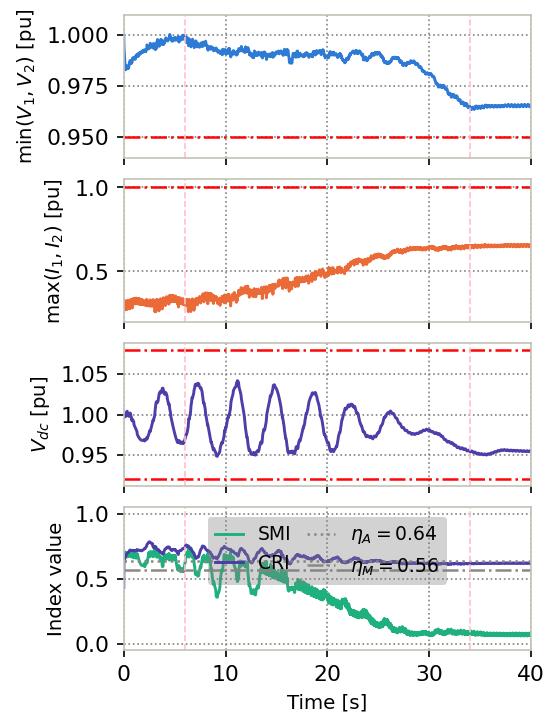

In [5]:
# ======================================================================
# Easy-to-tune figure settings
# ======================================================================

FIG_WIDTH = 3.5
FIG_HEIGHT = 5.5

LINE_ALPHA = 0.98

LW_MAIN = 1.4
LW_LIMIT = 1.2
LW_EVENT = 0.8

FONT_AXIS = 9.5
FONT_TICK = 10.5
FONT_LEGEND = 9.0

HEIGHT_RATIOS = [1.0, 1.0, 1.0, 1.0]
HSPACE = 0.15


# ======================================================================
# Legend settings -- same box style for all legends
# ======================================================================

# Position: (horizontal, vertical)
LEGEND_POS_SMI = (0.5, 0.98)     # Row 4: SMI + CRI

# Same box appearance for all legends
LEGEND_FRAME = True
LEGEND_FRAME_ALPHA = 0.35
LEGEND_FACE_COLOR = "gray"
LEGEND_EDGE_COLOR = "none"

LEGEND_COLUMN_SPACING = 0.8
LEGEND_HANDLE_LENGTH = 1.5


# ======================================================================
# Grid settings
# ======================================================================

GRID_COLOR = "gray"
GRID_ALPHA = 0.98
GRID_LW = 0.80
GRID_LS = ":"


# ======================================================================
# Event-window settings (load ramp t=6s -> t=34s)
# ======================================================================

EVENT_COLOR = "pink"
EVENT_LS = "--"


# ======================================================================
# Every line's color + linestyle
# ======================================================================

VMIN_STYLE = dict(
    color=plotstyle.CAT["blue"],
    ls="-",
    label=r"$\min(V_1,V_2)$"
)


IMAX_STYLE = dict(
    color=plotstyle.CAT["orange"],
    ls="-",
    label=r"$\max(I_1,I_2)$"
)


VDC_STYLE = dict(
    color=plotstyle.CAT["violet"],
    ls="-",
    label=r"$V_{dc}$"
)


SMI_CRI_STYLE = {
    "SMI": dict(
        color=plotstyle.INDICATOR_COLORS["SMI"],
        ls="-",
        label="SMI"
    ),

    "CRI": dict(
        color=plotstyle.INDICATOR_COLORS["CRI"],
        ls="-",
        label="CRI"
    ),
}


ETA_STYLE = {
    "eta_A": dict(
        value=crip.eta_A,
        color=plotstyle.INK_MUTED,
        ls=":",
        label=rf"$\eta_A={crip.eta_A:.2f}$"
    ),

    "eta_M": dict(
        value=crip.eta_M,
        color=plotstyle.INK_MUTED,
        ls="-.",
        label=rf"$\eta_M={crip.eta_M:.2f}$"
    ),
}


# ======================================================================
# Hard operational limits
# ======================================================================

LIMIT_COLOR = "red"

LIMIT_STYLE = dict(
    color=LIMIT_COLOR,
    ls="-.",
    lw=LW_LIMIT
)


# ======================================================================
# Grid helper
# ======================================================================

def style_grid(ax):
    ax.grid(
        True,
        color=GRID_COLOR,
        alpha=GRID_ALPHA,
        linewidth=GRID_LW,
        linestyle=GRID_LS
    )


# ======================================================================
# Event-marker helper
# ======================================================================

def mark_event(ax):
    ax.axvline(
        scenario.event_time,
        color=EVENT_COLOR,
        ls=EVENT_LS,
        lw=LW_EVENT
    )

    ax.axvline(
        scenario.event_end,
        color=EVENT_COLOR,
        ls=EVENT_LS,
        lw=LW_EVENT
    )


# ======================================================================
# Time vector
# ======================================================================

t = log["t"]
min_V = np.minimum(log["V1"], log["V2"])
max_I = np.maximum(log["I1"], log["I2"])


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    4,
    1,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharex=True,
    gridspec_kw=dict(
        height_ratios=HEIGHT_RATIOS,
        hspace=HSPACE
    )
)


# ======================================================================
# Row 1: min(V1, V2) vs. voltage limit
# ======================================================================

ax = axes[0]

ax.plot(
    t,
    min_V,
    color=VMIN_STYLE["color"],
    ls=VMIN_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=VMIN_STYLE["label"]
)

ax.axhline(
    cons.Vac_min,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.set_ylim(0.94, 1.01)

ax.set_ylabel(
    r"$\min(V_1,V_2)$ [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)
mark_event(ax)


# ======================================================================
# Row 2: max(I1, I2) vs. current limit
# ======================================================================

ax = axes[1]

ax.plot(
    t,
    max_I,
    color=IMAX_STYLE["color"],
    ls=IMAX_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=IMAX_STYLE["label"]
)

ax.axhline(
    cons.I_max,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.set_ylim(0.2, 1.05)

ax.set_ylabel(
    r"$\max(I_1,I_2)$ [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)
mark_event(ax)


# ======================================================================
# Row 3: DC-link voltage vs. DC-link limits
# ======================================================================

ax = axes[2]

ax.plot(
    t,
    log["Vdc"],
    color=VDC_STYLE["color"],
    ls=VDC_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=VDC_STYLE["label"]
)

ax.axhline(
    cons.Vdc_min,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.axhline(
    cons.Vdc_max,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.set_ylabel(
    r"$V_{dc}$ [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)
mark_event(ax)


# ======================================================================
# Row 4: SMI and CRI vs. classification thresholds
# ======================================================================

ax = axes[3]

for key, style in SMI_CRI_STYLE.items():
    ax.plot(
        t,
        log[key],
        color=style["color"],
        ls=style["ls"],
        lw=LW_MAIN,
        alpha=LINE_ALPHA,
        label=style["label"]
    )

for key, style in ETA_STYLE.items():
    ax.axhline(
        style["value"],
        color=style["color"],
        ls=style["ls"],
        lw=LW_LIMIT,
        alpha=LINE_ALPHA,
        label=style["label"]
    )

ax.set_ylim(-0.05, 1.05)

ax.set_ylabel(
    "Index value",
    fontsize=FONT_AXIS
)

ax.set_xlabel(
    "Time [s]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)
mark_event(ax)

# Same legend box style
ax.legend(
    frameon=LEGEND_FRAME,
    framealpha=LEGEND_FRAME_ALPHA,
    facecolor=LEGEND_FACE_COLOR,
    edgecolor=LEGEND_EDGE_COLOR,
    fontsize=FONT_LEGEND,
    ncol=2,
    columnspacing=LEGEND_COLUMN_SPACING,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="upper center"
)


# ======================================================================
# Save and display
# ======================================================================

for ax in axes:
    ax.set_xlim(t.min(), t.max())

plotstyle.savefig(
    fig,
    os.path.join(
        FIG_DIR,
        "Fig_constraint_margin_v2.pdf"
    )
)

plt.show()

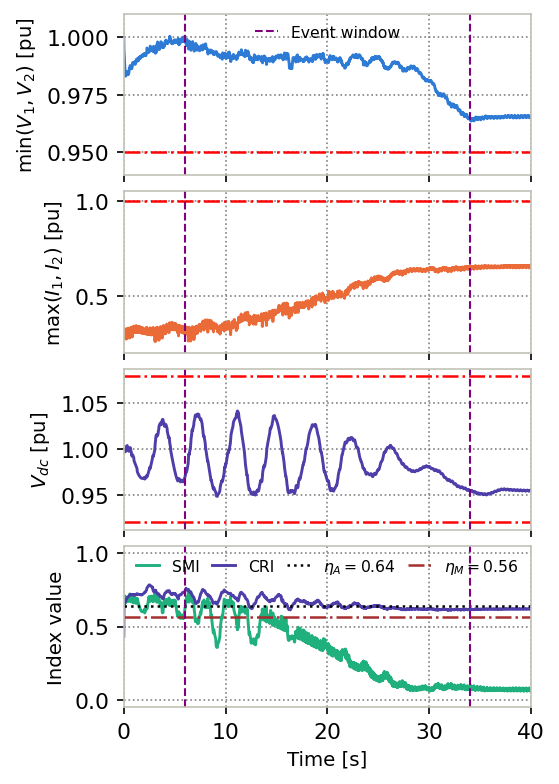

In [6]:
# ======================================================================
# Easy-to-tune figure settings
# ======================================================================

FIG_WIDTH = 3.5
FIG_HEIGHT = 6

LINE_ALPHA = 0.98

LW_MAIN = 1.4
LW_LIMIT = 1.2
LW_EVENT = 1

FONT_AXIS = 9.5
FONT_TICK = 10.5
FONT_LEGEND = 7.5

HEIGHT_RATIOS = [1.0, 1.0, 1.0, 1.0]
HSPACE = 0.10


# ======================================================================
# Legend settings
# ======================================================================

# Position: (horizontal, vertical)
LEGEND_POS_EVENT = (0.5, 1.02)    # Row 1: event window
LEGEND_POS_SMI = (0.5, 1.02)      # Row 4: SMI + CRI + thresholds

LEGEND_COLUMN_SPACING = 0.8
LEGEND_HANDLE_LENGTH = 1.5


# ======================================================================
# Grid settings
# ======================================================================

GRID_COLOR = "gray"
GRID_ALPHA = 0.98
GRID_LW = 0.80
GRID_LS = ":"


# ======================================================================
# Event-window settings
# ======================================================================

EVENT_COLOR = "purple"
EVENT_LS = "--"
EVENT_LABEL = "Event window"


# ======================================================================
# Every line's color + linestyle
# ======================================================================

VMIN_STYLE = dict(
    color=plotstyle.CAT["blue"],
    ls="-",
    label=r"$\min(V_1,V_2)$"
)


IMAX_STYLE = dict(
    color=plotstyle.CAT["orange"],
    ls="-",
    label=r"$\max(I_1,I_2)$"
)


VDC_STYLE = dict(
    color=plotstyle.CAT["violet"],
    ls="-",
    label=r"$V_{dc}$"
)


SMI_CRI_STYLE = {
    "SMI": dict(
        color=plotstyle.INDICATOR_COLORS["SMI"],
        ls="-",
        label="SMI"
    ),

    "CRI": dict(
        color=plotstyle.INDICATOR_COLORS["CRI"],
        ls="-",
        label="CRI"
    ),
}


# ======================================================================
# Classification thresholds
# ======================================================================

ETA_STYLE = {
    "eta_A": dict(
        value=crip.eta_A,
        color="black",
        ls=":",
        label=rf"$\eta_A={crip.eta_A:.2f}$"
    ),

    "eta_M": dict(
        value=crip.eta_M,
        color="brown",
        ls="-.",
        label=rf"$\eta_M={crip.eta_M:.2f}$"
    ),
}


# ======================================================================
# Hard operational limits
# ======================================================================

LIMIT_COLOR = "red"

LIMIT_STYLE = dict(
    color=LIMIT_COLOR,
    ls="-.",
    lw=LW_LIMIT
)


# ======================================================================
# Grid helper
# ======================================================================

def style_grid(ax):
    ax.grid(
        True,
        color=GRID_COLOR,
        alpha=GRID_ALPHA,
        linewidth=GRID_LW,
        linestyle=GRID_LS
    )


# ======================================================================
# Event-marker helper
# ======================================================================

def mark_event(ax):

    ax.axvline(
        scenario.event_time,
        color=EVENT_COLOR,
        ls=EVENT_LS,
        lw=LW_EVENT
    )

    ax.axvline(
        scenario.event_end,
        color=EVENT_COLOR,
        ls=EVENT_LS,
        lw=LW_EVENT
    )


# ======================================================================
# Time vector
# ======================================================================

t = log["t"]

min_V = np.minimum(
    log["V1"],
    log["V2"]
)

max_I = np.maximum(
    log["I1"],
    log["I2"]
)


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    4,
    1,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    sharex=True,
    gridspec_kw=dict(
        height_ratios=HEIGHT_RATIOS,
        hspace=HSPACE
    )
)


# ======================================================================
# Row 1: min(V1, V2) vs. voltage limit
# ======================================================================

ax = axes[0]

ax.plot(
    t,
    min_V,
    color=VMIN_STYLE["color"],
    ls=VMIN_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=VMIN_STYLE["label"]
)

ax.axhline(
    cons.Vac_min,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.set_ylim(
    0.94,
    1.01
)

ax.set_ylabel(
    r"$\min(V_1,V_2)$ [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)
mark_event(ax)


# ----------------------------------------------------------------------
# Event-window legend -- Row 1 only
# ----------------------------------------------------------------------

event_handle = plt.Line2D(
    [0],
    [0],
    color=EVENT_COLOR,
    ls=EVENT_LS,
    lw=LW_EVENT,
    label=EVENT_LABEL
)

ax.legend(
    handles=[event_handle],
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=1,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="upper center",
    bbox_to_anchor=LEGEND_POS_EVENT
)


# ======================================================================
# Row 2: max(I1, I2) vs. current limit
# ======================================================================

ax = axes[1]

ax.plot(
    t,
    max_I,
    color=IMAX_STYLE["color"],
    ls=IMAX_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=IMAX_STYLE["label"]
)

ax.axhline(
    cons.I_max,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.set_ylim(
    0.2,
    1.05
)

ax.set_ylabel(
    r"$\max(I_1,I_2)$ [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)
mark_event(ax)


# ======================================================================
# Row 3: DC-link voltage vs. DC-link limits
# ======================================================================

ax = axes[2]

ax.plot(
    t,
    log["Vdc"],
    color=VDC_STYLE["color"],
    ls=VDC_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=VDC_STYLE["label"]
)

ax.axhline(
    cons.Vdc_min,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.axhline(
    cons.Vdc_max,
    color=LIMIT_STYLE["color"],
    ls=LIMIT_STYLE["ls"],
    lw=LIMIT_STYLE["lw"],
    alpha=LINE_ALPHA
)

ax.set_ylabel(
    r"$V_{dc}$ [pu]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)
mark_event(ax)


# ======================================================================
# Row 4: SMI and CRI vs. classification thresholds
# ======================================================================

ax = axes[3]


# SMI and CRI
for key, style in SMI_CRI_STYLE.items():

    ax.plot(
        t,
        log[key],
        color=style["color"],
        ls=style["ls"],
        lw=LW_MAIN,
        alpha=LINE_ALPHA,
        label=style["label"]
    )


# eta_A and eta_M thresholds
for key, style in ETA_STYLE.items():

    ax.axhline(
        style["value"],
        color=style["color"],
        ls=style["ls"],
        lw=LW_LIMIT,
        alpha=LINE_ALPHA,
        label=style["label"]
    )


ax.set_ylim(
    -0.05,
    1.05
)

ax.set_ylabel(
    "Index value",
    fontsize=FONT_AXIS
)

ax.set_xlabel(
    "Time [s]",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)
mark_event(ax)


# ======================================================================
# Row 4 legend
# ======================================================================

ax.legend(
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=4,
    columnspacing=LEGEND_COLUMN_SPACING,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="upper center",
    bbox_to_anchor=LEGEND_POS_SMI
)


# ======================================================================
# Set common x-axis limits
# ======================================================================

for ax in axes:
    ax.set_xlim(
        t.min(),
        t.max()
    )


# ======================================================================
# Save and display
# ======================================================================

plotstyle.savefig(
    fig,
    os.path.join(
        FIG_DIR,
        "Fig_constraint_margin_v2.pdf"
    )
)

plt.show()

## Figure 4 -- Safe probing verification

Panel (a): SMI(t). Panel (b): normalized probe magnitude |delta u|/delta_max(t) -- the two
should visibly track each other. Panel (c): the scatter of probe magnitude vs. SMI must lie on
or below the y=x line (Eq. 10), verifying the probing amplitude never exceeds its SMI-scaled
budget.

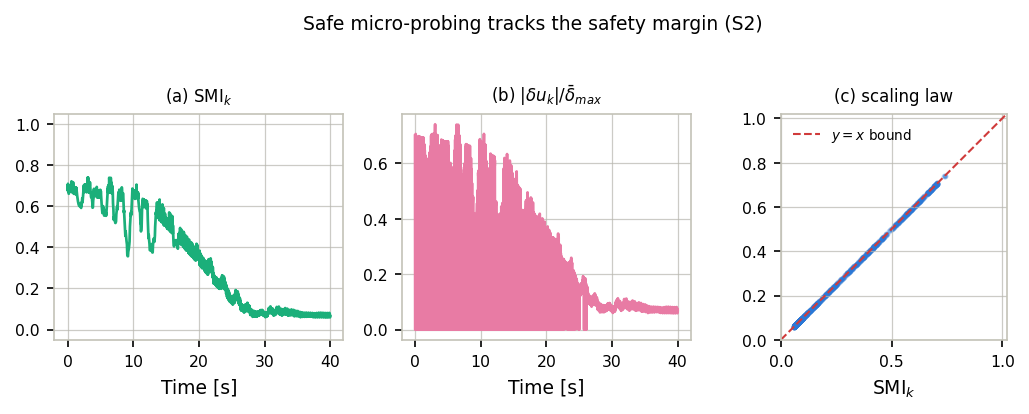

Fraction of probed samples exceeding the SMI-scaled bound: 0.0000%


In [7]:
probe_ratio = log["probe_norm"] / (crip.delta_max + 1e-12)

fig, axs = plt.subplots(1, 3, figsize=(plotstyle.IEEE_PAGE_WIDTH_IN, 2.6))

axs[0].plot(t, log["SMI"], color=plotstyle.INDICATOR_COLORS["SMI"])
axs[0].set_title("(a) SMI$_k$", fontsize=8); axs[0].set_xlabel("Time [s]"); axs[0].set_ylim(-0.05, 1.05)

axs[1].plot(t, probe_ratio, color=plotstyle.CAT["magenta"])
axs[1].set_title(r"(b) $|\delta u_k|/\bar\delta_{max}$", fontsize=8); axs[1].set_xlabel("Time [s]")

mask = log["probe_norm"] > 1e-9
axs[2].scatter(log["SMI"][mask], probe_ratio[mask], s=3, alpha=0.25, color=plotstyle.CAT["blue"])
lims = [0, 1.02]
axs[2].plot(lims, lims, color=plotstyle.STATUS["Reject"], lw=1.0, ls="--", label="$y=x$ bound")
axs[2].set_xlim(lims); axs[2].set_ylim(lims)
axs[2].set_xlabel("SMI$_k$"); axs[2].set_title(r"(c) scaling law", fontsize=8)
axs[2].legend(frameon=False, fontsize=6.5)
axs[2].set_aspect("equal")

fig.suptitle("Safe micro-probing tracks the safety margin (S2)", fontsize=9, y=1.03)
plotstyle.savefig(fig, os.path.join(FIG_DIR, "Fig_probe_scaling.pdf"))
plt.show()

frac_violating = float(np.mean(probe_ratio[mask] > log["SMI"][mask] + 1e-6)) if mask.any() else 0.0
print(f"Fraction of probed samples exceeding the SMI-scaled bound: {frac_violating:.4%}")
assert frac_violating < 1e-6, "probe amplitude exceeded its SMI-scaled bound"

## Figure 4 (v2) -- SMI and probe amplitude on shared time axis, same conventions as Figs. 3/4/5

The cell above is kept as the standard reference version (`Fig_probe_scaling.pdf`). This is the
revised layout: panels (a) SMI$_k$(t) and (b) $|\delta u_k|/\bar\delta_{max}$(t) exist to show
that the two track each other, so they are combined into one panel with two Y-axes instead of two
separate stacked plots. The Eq. (10) bound-verification scatter stays as its own panel below.

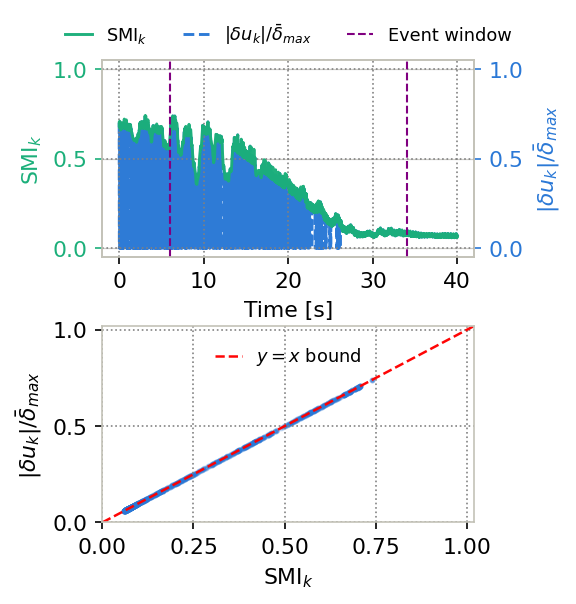

In [10]:
# ======================================================================
# Easy-to-tune figure settings
# ======================================================================

FIG_WIDTH = 3.2
FIG_HEIGHT = 4

LINE_ALPHA = 0.98

LW_MAIN = 1.4
LW_LIMIT = 1.2
LW_EVENT = 1

FONT_AXIS = 10.5
FONT_TICK = 10.5
FONT_LEGEND = 8.5

HEIGHT_RATIOS = [1.0, 1.0]
HSPACE = 0.35


# ======================================================================
# Legend settings
# ======================================================================

# Position: (horizontal, vertical)
LEGEND_POS_TIME = (0.5, 1.28)     # Row 1: SMI + probe ratio + event window
LEGEND_POS_SCATTER = (0.5, 0.98)  # Row 2: y=x bound

LEGEND_COLUMN_SPACING = 0.8
LEGEND_HANDLE_LENGTH = 1.5


# ======================================================================
# Grid settings
# ======================================================================

GRID_COLOR = "gray"
GRID_ALPHA = 0.98
GRID_LW = 0.80
GRID_LS = ":"


# ======================================================================
# Event-window settings
# ======================================================================

EVENT_COLOR = "purple"
EVENT_LS = "--"
EVENT_LABEL = "Event window"


# ======================================================================
# Every line's color + linestyle
# ======================================================================
# SMI is drawn solid and brought to the front; the probe ratio is drawn
# dashed on the twin axis -- the two values are nearly identical by
# Eq. (10), so a matching linestyle would make one line invisible under
# the other.

SMI_STYLE = dict(
    color=plotstyle.INDICATOR_COLORS["SMI"],
    ls="-",
    label="SMI$_k$"
)


PROBE_STYLE = dict(
    color=plotstyle.CAT["blue"],
    ls="--",
    label=r"$|\delta u_k|/\bar\delta_{max}$"
)


BOUND_STYLE = dict(
    color="red",
    ls="--",
    label="$y=x$ bound"
)


SCATTER_STYLE = dict(
    color=plotstyle.CAT["blue"]
)


# ======================================================================
# Grid helper
# ======================================================================

def style_grid(ax):
    ax.grid(
        True,
        color=GRID_COLOR,
        alpha=GRID_ALPHA,
        linewidth=GRID_LW,
        linestyle=GRID_LS
    )


# ======================================================================
# Event-marker helper
# ======================================================================

def mark_event(ax):

    ax.axvline(
        scenario.event_time,
        color=EVENT_COLOR,
        ls=EVENT_LS,
        lw=LW_EVENT
    )

    ax.axvline(
        scenario.event_end,
        color=EVENT_COLOR,
        ls=EVENT_LS,
        lw=LW_EVENT
    )


# ======================================================================
# Data
# ======================================================================

t = log["t"]

probe_ratio = log["probe_norm"] / (crip.delta_max + 1e-12)

mask = log["probe_norm"] > 1e-9


# ======================================================================
# Create figure
# ======================================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    gridspec_kw=dict(
        height_ratios=HEIGHT_RATIOS,
        hspace=HSPACE
    )
)


# ======================================================================
# Row 1: SMI (left axis) and probe ratio (right axis) vs. time
# ======================================================================

ax1 = axes[0]
ax2 = ax1.twinx()

# Bring ax1 (SMI, solid) to the front so it draws over ax2 (probe, dashed)
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

ax2.plot(
    t,
    probe_ratio,
    color=PROBE_STYLE["color"],
    ls=PROBE_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=PROBE_STYLE["label"]
)

ax1.plot(
    t,
    log["SMI"],
    color=SMI_STYLE["color"],
    ls=SMI_STYLE["ls"],
    lw=LW_MAIN,
    alpha=LINE_ALPHA,
    label=SMI_STYLE["label"]
)

ax1.set_ylim(-0.05, 1.05)
ax2.set_ylim(-0.05, 1.05)

ax1.set_ylabel(
    "SMI$_k$",
    fontsize=FONT_AXIS,
    color=SMI_STYLE["color"]
)

ax2.set_ylabel(
    r"$|\delta u_k|/\bar\delta_{max}$",
    fontsize=FONT_AXIS,
    color=PROBE_STYLE["color"]
)

ax1.tick_params(
    axis="y",
    labelsize=FONT_TICK,
    colors=SMI_STYLE["color"]
)

ax2.tick_params(
    axis="y",
    labelsize=FONT_TICK,
    colors=PROBE_STYLE["color"]
)

ax1.tick_params(
    axis="x",
    labelsize=FONT_TICK
)

ax1.set_xlabel(
    "Time [s]",
    fontsize=FONT_AXIS
)

style_grid(ax1)
mark_event(ax1)

event_handle = plt.Line2D(
    [0],
    [0],
    color=EVENT_COLOR,
    ls=EVENT_LS,
    lw=LW_EVENT,
    label=EVENT_LABEL
)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles=handles1 + handles2 + [event_handle],
    labels=labels1 + labels2 + [EVENT_LABEL],
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=3,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="upper center",
    bbox_to_anchor=LEGEND_POS_TIME
)


# ======================================================================
# Row 2: scaling law -- probe ratio vs. SMI, must stay on/below y=x
# ======================================================================

ax = axes[1]

ax.scatter(
    log["SMI"][mask],
    probe_ratio[mask],
    s=3,
    alpha=0.25,
    color=SCATTER_STYLE["color"]
)

lims = [0, 1.02]

ax.plot(
    lims,
    lims,
    color=BOUND_STYLE["color"],
    ls=BOUND_STYLE["ls"],
    lw=LW_LIMIT,
    alpha=LINE_ALPHA,
    label=BOUND_STYLE["label"]
)

ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_xlabel(
    "SMI$_k$",
    fontsize=FONT_AXIS
)

ax.set_ylabel(
    r"$|\delta u_k|/\bar\delta_{max}$",
    fontsize=FONT_AXIS
)

ax.tick_params(
    labelsize=FONT_TICK
)

style_grid(ax)

ax.legend(
    frameon=False,
    fontsize=FONT_LEGEND,
    ncol=1,
    handlelength=LEGEND_HANDLE_LENGTH,
    loc="upper center",
    bbox_to_anchor=LEGEND_POS_SCATTER
)


# ======================================================================
# Save and display
# ======================================================================

plotstyle.savefig(
    fig,
    os.path.join(
        FIG_DIR,
        "Fig_probe_scaling_v2.pdf"
    )
)

plt.show()

In [8]:
cols = ["t", "RI", "CI", "SMI", "AI", "NCI", "CRI", "kappa", "s", "cls_code",
        "V1", "V2", "Vdc", "I1", "I2", "probe_bar", "probe_norm"]
df = pd.DataFrame({c: log[c] for c in cols})
df.to_csv(os.path.join(RESULTS_DIR, "results_S2.csv"), index=False)
print("Saved", len(df), "rows to results_S2.csv")

Saved 2001 rows to results_S2.csv


## Takeaway

As the operating point is driven toward -- but not across -- the voltage/current/DC-link limits,
SMI falls well before any hard constraint is actually violated, pulling the CRI down and pulling
the safe-probing amplitude down with it in exact proportion. The framework acts pre-emptively,
not reactively.